# Project 8: Principal Component Analysis (PCA) from Scratch

## Introduction

The goal of this project is to understand and implement **Principal Component Analysis (PCA)** from scratch using NumPy.

PCA is an unsupervised dimensionality reduction technique that transforms a dataset with multiple features into a smaller set of new variables called *principal components*. These components capture as much of the original data variance as possible while reducing the number of dimensions.

In this project, we use the **Red Wine Quality dataset**, which contains 11 numerical physicochemical features after excluding the `quality` column. We apply PCA to reduce these 11 dimensions to 2 principal components and visualize the resulting data in a two-dimensional space.

The main steps include:
- Standardizing the numerical features.
- Computing the covariance matrix.
- Calculating and sorting eigenvalues and eigenvectors.
- Selecting the first two principal components.
- Projecting the original data into a two-dimensional space.
- Calculating explained variance.
- Visualizing the transformed data.
- Comparing our implementation with Scikit-learn's PCA.

The final goal is to understand the mathematical foundations of PCA and verify that our implementation produces results consistent with a standard machine learning library.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('winequality-red.csv', sep = ';')

In [3]:
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [4]:
# Our goal is to reduce the dimension of physio-chemistry features
# we can drop Quality
df1 = df.drop(columns='quality')

## Data Standardization

PCA is sensitive to the scale of features because features with larger numerical ranges can dominate the variance calculation.

To prevent this, we standardize each feature using Z-score normalization. This transforms the data so that each feature has a mean of approximately zero and a standard deviation of one.

The standardization formula is:

`z = (x - mean) / std`

Where:

- `x` is the original feature value.
- `mean` is the feature mean.
- `std` is the feature standard deviation.
- `z` is the standardized value.

This ensures that all features contribute on a comparable scale to the PCA calculation.

In [5]:
# Standardize the Data
# z_scores = (data - mean) / std
mean = df1.mean()
std = df1.std()
z_score = (df1 - mean)/std

In [6]:
z_score

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,-0.528194,0.961576,-1.391037,-0.453077,-0.243630,-0.466047,-0.379014,0.558100,1.288240,-0.579025,-0.959946
1,-0.298454,1.966827,-1.391037,0.043403,0.223805,0.872365,0.624168,0.028252,-0.719708,0.128910,-0.584594
2,-0.298454,1.296660,-1.185699,-0.169374,0.096323,-0.083643,0.228975,0.134222,-0.331073,-0.048074,-0.584594
3,1.654339,-1.384011,1.483689,-0.453077,-0.264878,0.107558,0.411372,0.664069,-0.978798,-0.461036,-0.584594
4,-0.528194,0.961576,-1.391037,-0.453077,-0.243630,-0.466047,-0.379014,0.558100,1.288240,-0.579025,-0.959946
...,...,...,...,...,...,...,...,...,...,...,...
1594,-1.217415,0.403103,-0.980362,-0.382151,0.053829,1.541571,-0.075020,-0.978459,0.899605,-0.461036,0.072271
1595,-1.389721,0.123866,-0.877693,-0.240300,-0.541090,2.210777,0.137777,-0.861893,1.353012,0.600867,0.729136
1596,-1.159980,-0.099523,-0.723690,-0.169374,-0.243630,1.254769,-0.196617,-0.533387,0.705287,0.541872,0.541460
1597,-1.389721,0.654416,-0.775024,-0.382151,-0.264878,1.541571,-0.075020,-0.676446,1.676875,0.305894,-0.209243


In [7]:
print(z_score.mean())
print('')
print(z_score.std())
print('')
print(z_score.shape)

fixed acidity           3.554936e-16
volatile acidity        1.688594e-16
citric acid            -1.066481e-16
residual sugar         -1.110917e-16
chlorides               3.554936e-16
free sulfur dioxide    -6.221137e-17
total sulfur dioxide    2.666202e-17
density                -3.469617e-14
pH                      2.861723e-15
sulphates               6.665504e-16
alcohol                 7.109871e-17
dtype: float64

fixed acidity           1.0
volatile acidity        1.0
citric acid             1.0
residual sugar          1.0
chlorides               1.0
free sulfur dioxide     1.0
total sulfur dioxide    1.0
density                 1.0
pH                      1.0
sulphates               1.0
alcohol                 1.0
dtype: float64

(1599, 11)



## Covariance Matrix

The covariance matrix describes the relationships between numerical features by measuring how they vary together.

Each element of the covariance matrix represents the covariance between a pair of features:

- Positive covariance indicates that two features tend to increase or decrease together.
- Negative covariance indicates that they tend to move in opposite directions.
- Covariance close to zero indicates a weak linear relationship.

The diagonal elements represent the variance of individual features.

Since our features have been standardized, the diagonal values should be approximately equal to one.

The covariance matrix is an important step in PCA because it provides the information needed to identify the directions of maximum variance.

In [8]:
# Build the Covariance Matrix
cov_mat = np.cov(z_score, rowvar = False)
print(cov_mat)
print(cov_mat.shape)

[[ 1.         -0.25613089  0.67170343  0.11477672  0.09370519 -0.15379419
  -0.11318144  0.66804729 -0.68297819  0.18300566 -0.06166827]
 [-0.25613089  1.         -0.55249568  0.00191788  0.06129777 -0.01050383
   0.07647     0.02202623  0.23493729 -0.26098669 -0.20228803]
 [ 0.67170343 -0.55249568  1.          0.14357716  0.20382291 -0.06097813
   0.03553302  0.36494718 -0.54190414  0.31277004  0.10990325]
 [ 0.11477672  0.00191788  0.14357716  1.          0.05560954  0.187049
   0.20302788  0.35528337 -0.08565242  0.00552712  0.04207544]
 [ 0.09370519  0.06129777  0.20382291  0.05560954  1.          0.00556215
   0.04740047  0.20063233 -0.26502613  0.37126048 -0.22114054]
 [-0.15379419 -0.01050383 -0.06097813  0.187049    0.00556215  1.
   0.66766645 -0.02194583  0.0703775   0.05165757 -0.06940835]
 [-0.11318144  0.07647     0.03553302  0.20302788  0.04740047  0.66766645
   1.          0.07126948 -0.06649456  0.04294684 -0.20565394]
 [ 0.66804729  0.02202623  0.36494718  0.35528337  

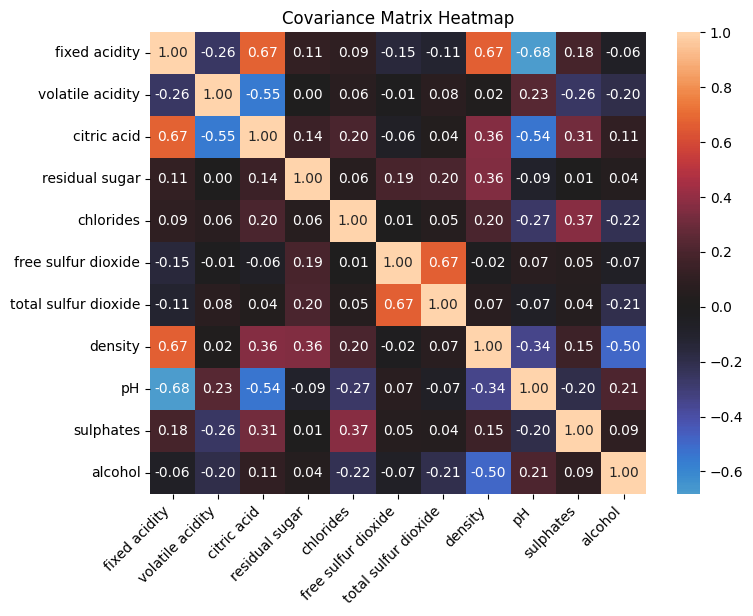

In [9]:
plt.figure(figsize=(8,6))
sns.heatmap(
    cov_mat,
    annot = True,
    fmt = '.2f',
    xticklabels=z_score.columns,
    yticklabels=z_score.columns,
    center=0
)
plt.title("Covariance Matrix Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.show()

In [10]:
np.allclose(cov_mat , cov_mat.T)

True

## Eigenvalues and Eigenvectors

Eigenvalues and eigenvectors are the mathematical foundation of PCA.

By decomposing the covariance matrix, we obtain:

- **Eigenvectors:** Represent the directions of the principal components. Each eigenvector defines a direction in the original feature space.
- **Eigenvalues:** Represent the amount of variance captured along their corresponding eigenvector directions.

A larger eigenvalue indicates that its corresponding principal component captures more variance from the dataset.

In PCA, the eigenvector with the largest eigenvalue represents the first principal component (PC1), while the eigenvector with the second-largest eigenvalue represents the second principal component (PC2).

In [11]:
# Calculate Eigenvalues and Eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(cov_mat)

print('Eigenvalues: ') 
print(eigenvalues)
print('\nEigenvectors: ')
print(eigenvectors)

Eigenvalues: 
[3.09913244 1.92590969 1.55054349 1.21323253 0.95929207 0.05955831
 0.18133317 0.34464212 0.4229567  0.58379122 0.65960826]

Eigenvectors: 
[[ 0.48931422 -0.11050274 -0.12330157 -0.22961737 -0.08261366 -0.63969145
  -0.24952314  0.19402091 -0.17759545 -0.35022736  0.10147858]
 [-0.23858436  0.27493048 -0.44996253  0.07895978  0.21873452 -0.0023886
   0.36592473 -0.1291103  -0.07877531 -0.5337351   0.41144893]
 [ 0.46363166 -0.15179136  0.23824707 -0.07941826 -0.05857268  0.0709103
   0.62167708 -0.38144967 -0.37751558  0.10549701  0.06959338]
 [ 0.14610715  0.27208024  0.10128338 -0.37279256  0.73214429 -0.18402996
   0.09287208  0.00752295  0.29984469  0.29066341  0.04915555]
 [ 0.21224658  0.14805156 -0.09261383  0.66619476  0.2465009  -0.05306532
  -0.21767112  0.11133867 -0.35700936  0.37041337  0.30433857]
 [-0.03615752  0.51356681  0.42879287 -0.04353782 -0.15915198  0.05142086
   0.24848326  0.63540522 -0.2047805  -0.11659611 -0.01400021]
 [ 0.02357485  0.56948696 

## Sorting Eigenvalues and Selecting Principal Components

The eigenvalues obtained from the decomposition are not necessarily returned in descending order.

Therefore, we sort the eigenvalues from largest to smallest and rearrange their corresponding eigenvectors using the same indices.

This step is essential because each eigenvector must remain associated with its original eigenvalue.

After sorting, we select the first two eigenvectors because our objective is to reduce the dataset from 11 dimensions to 2 dimensions.

These two eigenvectors form the principal component matrix.

In [12]:
# Sort Eigenvalues
sorted_indices = np.argsort(eigenvalues)[::-1]

sorted_eigenvalues = eigenvalues[sorted_indices]
sorted_eigenvectors = eigenvectors[:, sorted_indices]

print(sorted_eigenvalues)
print(sorted_eigenvectors)

[3.09913244 1.92590969 1.55054349 1.21323253 0.95929207 0.65960826
 0.58379122 0.4229567  0.34464212 0.18133317 0.05955831]
[[ 0.48931422 -0.11050274 -0.12330157 -0.22961737 -0.08261366  0.10147858
  -0.35022736 -0.17759545  0.19402091 -0.24952314 -0.63969145]
 [-0.23858436  0.27493048 -0.44996253  0.07895978  0.21873452  0.41144893
  -0.5337351  -0.07877531 -0.1291103   0.36592473 -0.0023886 ]
 [ 0.46363166 -0.15179136  0.23824707 -0.07941826 -0.05857268  0.06959338
   0.10549701 -0.37751558 -0.38144967  0.62167708  0.0709103 ]
 [ 0.14610715  0.27208024  0.10128338 -0.37279256  0.73214429  0.04915555
   0.29066341  0.29984469  0.00752295  0.09287208 -0.18402996]
 [ 0.21224658  0.14805156 -0.09261383  0.66619476  0.2465009   0.30433857
   0.37041337 -0.35700936  0.11133867 -0.21767112 -0.05306532]
 [-0.03615752  0.51356681  0.42879287 -0.04353782 -0.15915198 -0.01400021
  -0.11659611 -0.2047805   0.63540522  0.24848326  0.05142086]
 [ 0.02357485  0.56948696  0.3224145  -0.03457712 -0.2

In [13]:
#Select Principal Components
principal_components = sorted_eigenvectors[:,:2]
print(principal_components)
print(principal_components.shape)

[[ 0.48931422 -0.11050274]
 [-0.23858436  0.27493048]
 [ 0.46363166 -0.15179136]
 [ 0.14610715  0.27208024]
 [ 0.21224658  0.14805156]
 [-0.03615752  0.51356681]
 [ 0.02357485  0.56948696]
 [ 0.39535301  0.23357549]
 [-0.43851962  0.00671079]
 [ 0.24292133 -0.03755392]
 [-0.11323206 -0.38618096]]
(11, 2)


In [14]:
z_score.shape

(1599, 11)

## Data Projection

After selecting the principal components, we project the standardized data onto the new two-dimensional space.

This is performed through matrix multiplication:

`X_PCA = Z @ W`

Where:

- `Z` is the standardized data matrix.
- `W` is the matrix containing the selected principal component vectors.
- `X_PCA` is the transformed dataset.

The resulting dataset contains 1,599 samples and 2 columns, representing PC1 and PC2.

Each sample is now represented by two new values instead of its original 11 features.

In [15]:
#Project the Data into the New Space
# X_new = X_scaled * W
x_pca = z_score @ principal_components

print(x_pca.shape)
print(x_pca[:5])

(1599, 2)
          0         1
0 -1.619023  0.450809
1 -0.798920  1.855972
2 -0.748245  0.881763
3  2.356935 -0.269892
4 -1.619023  0.450809


## Explained Variance

Explained variance measures how much of the total variance in the original dataset is retained by each principal component.

The explained variance ratio is calculated by dividing each eigenvalue by the sum of all eigenvalues:

`Explained Variance Ratio = Eigenvalue / Sum of All Eigenvalues`

We also calculate the cumulative explained variance, which shows how much variance is retained when multiple principal components are combined.

This helps us evaluate how much information is preserved after dimensionality reduction.

In [16]:
#Calculate Explained Variance
total_variance = np.sum(sorted_eigenvalues)

explained_variance_ratio = sorted_eigenvalues/total_variance

cumulative_variance = np.cumsum(explained_variance_ratio)

print("Explained Variance Ratio:")
print(explained_variance_ratio)

print("\nCumulative Explained Variance:")
print(cumulative_variance)
print("\nVariance explained by first two components:")
print(f"{cumulative_variance[1] * 100:.2f}%")

Explained Variance Ratio:
[0.28173931 0.1750827  0.1409585  0.11029387 0.08720837 0.05996439
 0.05307193 0.03845061 0.0313311  0.01648483 0.00541439]

Cumulative Explained Variance:
[0.28173931 0.45682201 0.59778051 0.70807438 0.79528275 0.85524714
 0.90831906 0.94676967 0.97810077 0.99458561 1.        ]

Variance explained by first two components:
45.68%


## 2D Visualization

We visualize the transformed dataset using a scatter plot, where the horizontal axis represents PC1 and the vertical axis represents PC2.

Each point represents one wine sample.

This visualization helps us examine the overall distribution of the samples, identify potential outliers, and observe whether the data forms any visible clusters in the reduced feature space.

Since the `quality` column was excluded from PCA, the plot does not directly represent wine quality categories.

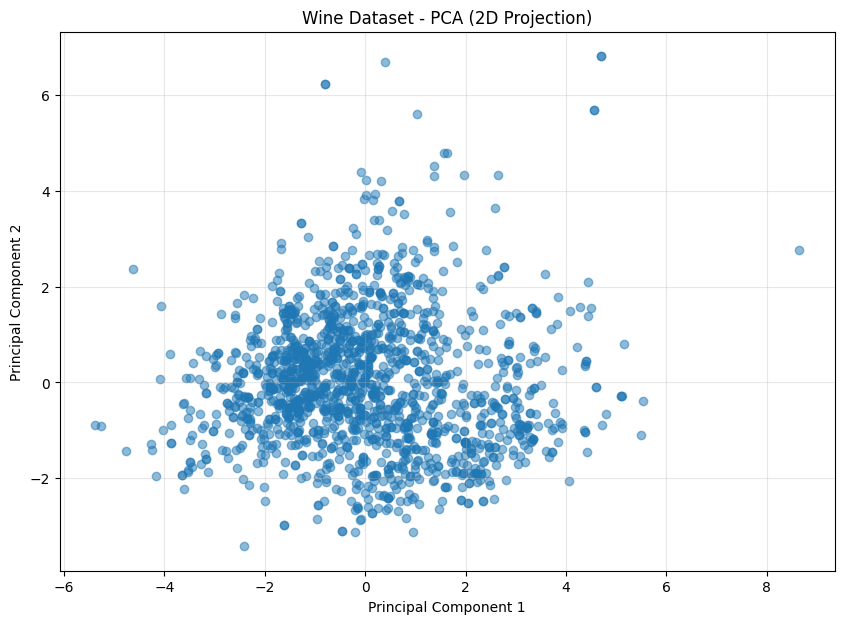

In [17]:
# Visualize the Data in 2D
plt.figure(figsize=(10, 7))

plt.scatter(
    x_pca.iloc[:, 0],
    x_pca.iloc[:, 1],
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Dataset - PCA (2D Projection)")

plt.grid(alpha=0.3)
plt.show()

## Comparison with Scikit-learn

To verify our implementation, we perform the same dimensionality reduction using `sklearn.decomposition.PCA`.

We compare the explained variance ratios and the shape of the transformed dataset.

The results should be approximately equal, although the signs of individual principal component vectors and their corresponding projected coordinates may differ. This is because the direction of an eigenvector can be reversed without changing the underlying principal component.

Matching explained variance ratios confirms that our manual implementation is consistent with Scikit-learn's PCA.

In [18]:
# Compare with Scikit-learn
from sklearn.decomposition import PCA

pca = PCA(n_components = 2)

x_pca_sk = pca.fit_transform(z_score)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(pca.explained_variance_ratio_.sum())

print("\nTransformed Data Shape:")
print(x_pca_sk.shape)

Explained Variance Ratio:
[0.28173931 0.1750827 ]

Total Explained Variance:
0.4568220118429404

Transformed Data Shape:
(1599, 2)


## Conclusion

In this project, we successfully implemented Principal Component Analysis (PCA) from scratch using NumPy and applied it to the Red Wine Quality dataset.

We reduced the number of features from 11 to 2 principal components while retaining approximately **45.68% of the total variance**:

- PC1 explained approximately 28.17% of the variance.
- PC2 explained approximately 17.51% of the variance.
- Together, the first two components explained approximately 45.68% of the total variance.

The two-dimensional scatter plot provided a visual representation of the transformed dataset, showing its overall distribution and several potential outliers.

Finally, we compared our implementation with Scikit-learn's PCA and obtained matching explained variance ratios, confirming the correctness of our implementation.

Overall, this project provided a practical understanding of the mathematical foundations of PCA, including covariance matrices, eigenvalues, eigenvectors, and dimensionality reduction.